In [2]:
csv_path = "datos/STAR.csv"
df = (spark.read.format("csv").option("header",True).option("inferSchema",
True).option("nullValue", "NA").load(csv_path))

In [3]:
from pyspark.sql.types import DoubleType
from pyspark.sql import functions as F

df_limpio = df.withColumn("readk", F.col("readk").cast(DoubleType()))
df_limpio = df_limpio.withColumn("read1", F.col("read1").cast(DoubleType()))
df_limpio = df_limpio.withColumn("read2", F.col("read2").cast(DoubleType()))
df_limpio = df_limpio.withColumn("read3", F.col("read3").cast(DoubleType()))

df_limpio = df_limpio.withColumn("mathk", F.col("mathk").cast(DoubleType()))
df_limpio = df_limpio.withColumn("math1", F.col("math1").cast(DoubleType()))
df_limpio = df_limpio.withColumn("math2", F.col("math2").cast(DoubleType()))
df_limpio = df_limpio.withColumn("math3", F.col("math3").cast(DoubleType()))

df_limpio = df_limpio.withColumn("experiencek", F.col("experiencek").cast(DoubleType()))
df_limpio = df_limpio.withColumn("experience1", F.col("experience1").cast(DoubleType()))
df_limpio = df_limpio.withColumn("experience2", F.col("experience2").cast(DoubleType()))
df_limpio = df_limpio.withColumn("experience3", F.col("experience3").cast(DoubleType()))

In [4]:
# Ruta donde guardaremos los datos
delta_path = "datos/star"
(
    df_limpio.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .save(delta_path)
)
df = spark.read.format("delta").load(delta_path)

In [5]:
df = spark.read.format("delta").load("datos/star")

df.show(5)
df.printSchema()

+----+------+---------+-------+------------+-----+------------+------------+-----+-----+-----+-----+-----+-----+-----+-----+--------+------+--------+--------+----------+--------+--------+--------+--------+--------+--------+--------+---------+---------+----------+----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-----------+-------+-------+-------+-------+---------+---------+---------+---------+
|  c0|gender|ethnicity|  birth|       stark|star1|       star2|       star3|readk|read1|read2|read3|mathk|math1|math2|math3|  lunchk|lunch1|  lunch2|  lunch3|   schoolk| school1| school2| school3| degreek| degree1| degree2| degree3|  ladderk|  ladder1|   ladder2|   ladder3|experiencek|experience1|experience2|experience3|tethnicityk|tethnicity1|tethnicity2|tethnicity3|systemk|system1|system2|system3|schoolidk|schoolid1|schoolid2|schoolid3|
+----+------+---------+-------+------------+-----+------------+------------+-----+-----+-----+-----+-----+-----+--

In [6]:
# %% 6. Codificación de variables categóricas

from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder

# Variables comunes a todos los cursos
comunes = ["gender", "ethnicity", "birth"]

# Variables específicas de cada curso
variables = [
    "star", "lunch", "school", "degree",
    "ladder", "tethnicity", "system", "schoolid"
]

cursos = ["k", "1", "2", "3"]

# Generar los nombres de todas las columnas categóricas
columnas = comunes + [
    f"{variable}{curso}"
    for curso in cursos
    for variable in variables
]

# Preparar los nombres de las columnas transformadas
columnasI = [col + "I" for col in columnas]
columnasE = [col + "E" for col in columnas]

# Convertir categorías en índices numéricos
indexer = StringIndexer(
    inputCols=columnas,
    outputCols=columnasI,
    handleInvalid="keep"
)

# Convertir índices en vectores One-Hot
encoder = OneHotEncoder(
    inputCols=columnasI,
    outputCols=columnasE
)

# Encadenar las dos transformaciones
pipeline = Pipeline(stages=[indexer, encoder])

# Ajustar y aplicar las transformaciones
df_codificado = pipeline.fit(df).transform(df)

In [7]:
df_codificado.select(
    "gender", "genderI", "genderE",
    "stark", "starkI", "starkE"
).show(10, truncate=False)

+------+-------+-------------+------------+------+-------------+
|gender|genderI|genderE      |stark       |starkI|starkE       |
+------+-------+-------------+------------+------+-------------+
|female|1.0    |(2,[1],[1.0])|NULL        |3.0   |(3,[],[])    |
|female|1.0    |(2,[1],[1.0])|small       |2.0   |(3,[2],[1.0])|
|female|1.0    |(2,[1],[1.0])|small       |2.0   |(3,[2],[1.0])|
|male  |0.0    |(2,[0],[1.0])|NULL        |3.0   |(3,[],[])    |
|male  |0.0    |(2,[0],[1.0])|regular+aide|0.0   |(3,[0],[1.0])|
|male  |0.0    |(2,[0],[1.0])|NULL        |3.0   |(3,[],[])    |
|male  |0.0    |(2,[0],[1.0])|NULL        |3.0   |(3,[],[])    |
|female|1.0    |(2,[1],[1.0])|NULL        |3.0   |(3,[],[])    |
|male  |0.0    |(2,[0],[1.0])|NULL        |3.0   |(3,[],[])    |
|male  |0.0    |(2,[0],[1.0])|NULL        |3.0   |(3,[],[])    |
+------+-------+-------------+------------+------+-------------+
only showing top 10 rows


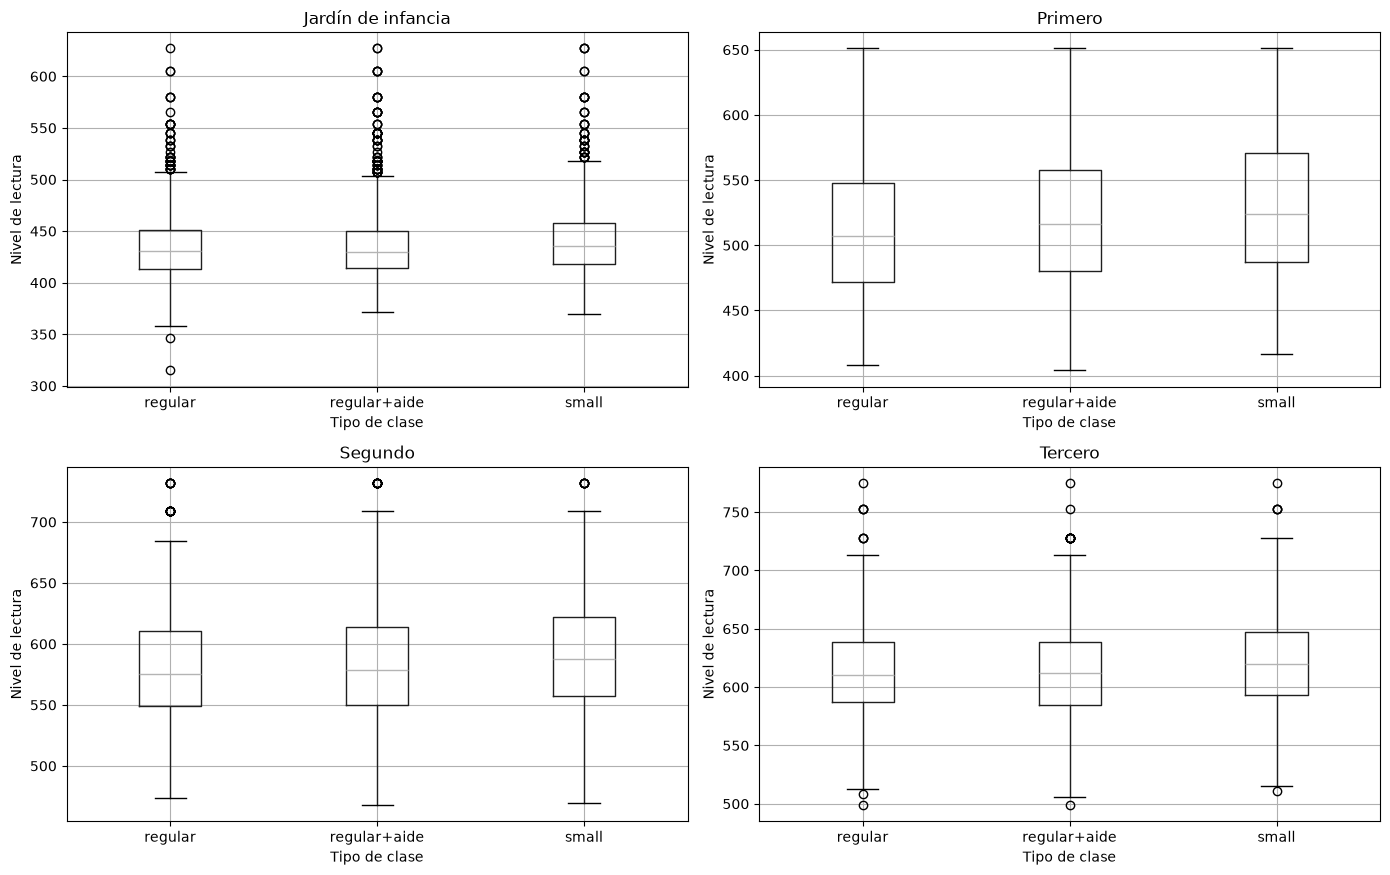

In [8]:

# %% 7. Diagramas de cajas - Nivel de lectura

import matplotlib.pyplot as plt

# Cursos que vamos a analizar
cursos = ["k", "1", "2", "3"]
nombres = ["Jardín de infancia", "Primero", "Segundo", "Tercero"]

# Crear una figura con 4 gráficos (2 filas y 2 columnas)
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))

for curso, nombre, eje in zip(cursos, nombres, ejes.flat):

    # Seleccionar las columnas del curso correspondiente
    columna_clase = f"star{curso}"
    columna_lectura = f"read{curso}"

    # Seleccionar datos, eliminar nulos y convertir a Pandas
    datos = (
        df.select(columna_clase, columna_lectura)
        .dropna()
        .toPandas()
    )

    # Dibujar el diagrama de cajas
    datos.boxplot(
        column=columna_lectura,
        by=columna_clase,
        ax=eje
    )

    # Personalizar el gráfico
    eje.set_title(nombre)
    eje.set_xlabel("Tipo de clase")
    eje.set_ylabel("Nivel de lectura")

# Ajustar la presentación
plt.suptitle("")
plt.tight_layout()
plt.show()


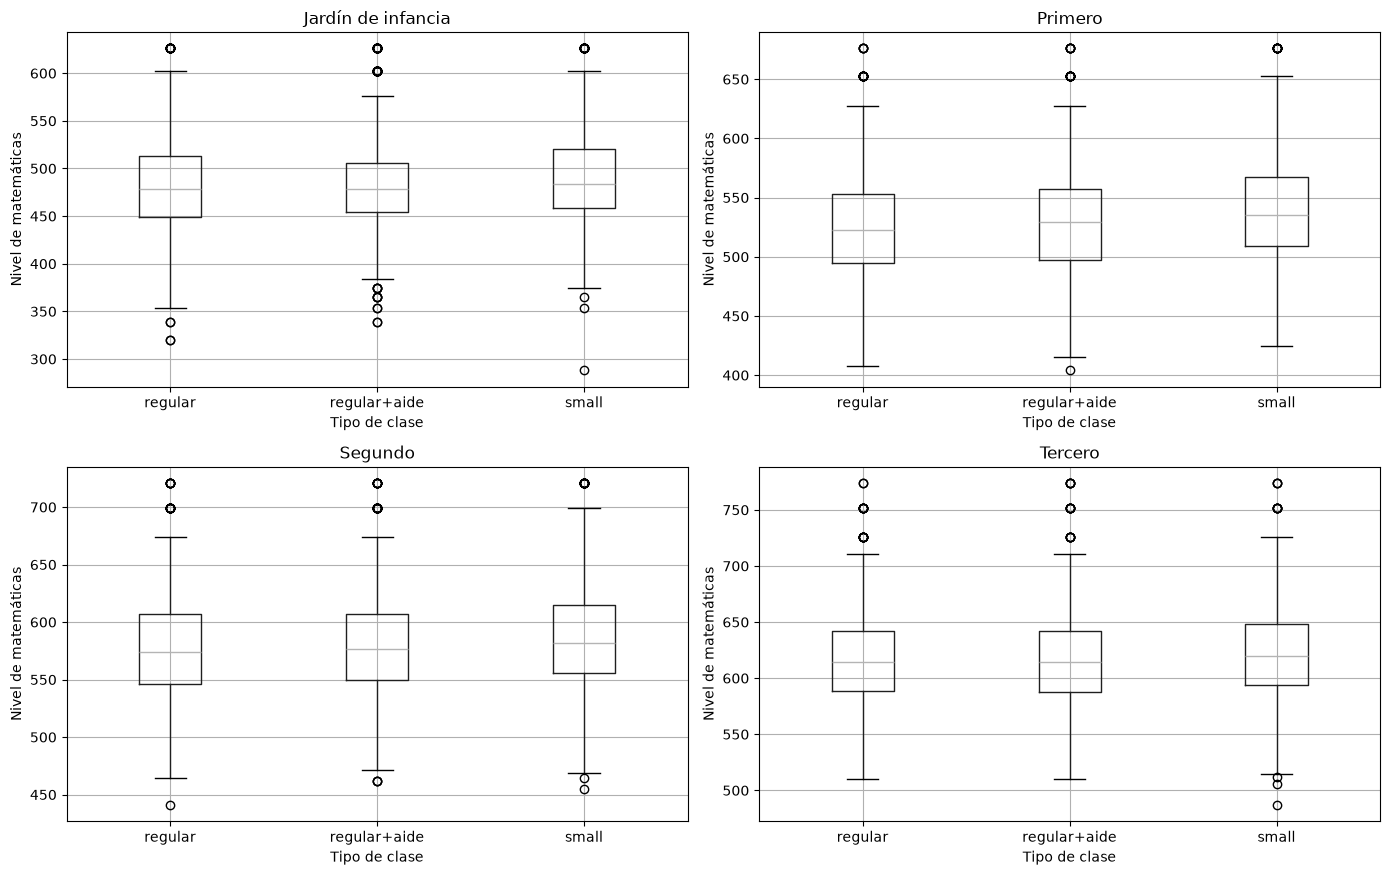

In [9]:

# %% 8. Diagramas de cajas - Nivel de matemáticas

import matplotlib.pyplot as plt

# Cursos que vamos a analizar
cursos = ["k", "1", "2", "3"]
nombres = ["Jardín de infancia", "Primero", "Segundo", "Tercero"]

# Crear cuatro gráficos
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))

for curso, nombre, eje in zip(cursos, nombres, ejes.flat):

    # Seleccionar las columnas del curso
    columna_clase = f"star{curso}"
    columna_matematicas = f"math{curso}"

    # Seleccionar datos, eliminar nulos y convertir a Pandas
    datos = (
        df.select(columna_clase, columna_matematicas)
        .dropna()
        .toPandas()
    )

    # Dibujar el diagrama de cajas
    datos.boxplot(
        column=columna_matematicas,
        by=columna_clase,
        ax=eje
    )

    # Personalizar el gráfico
    eje.set_title(nombre)
    eje.set_xlabel("Tipo de clase")
    eje.set_ylabel("Nivel de matemáticas")

plt.suptitle("")
plt.tight_layout()
plt.show()


In [10]:
# %% 9. Regresión lineal - Jardín de infancia

# Variables predictoras indicadas en el enunciado
colinputk = [
    "genderI", "ethnicityI", "birthI",
    "starkI", "lunchkI", "schoolkI",
    "degreekI", "ladderkI", "tethnicitykI"
]

# Dividir los datos en entrenamiento y test
train, test = df_codificado.randomSplit(
    [0.7, 0.3],
    seed=42
)

# Comprobar cuántos registros tiene cada conjunto
print("Entrenamiento:", train.count())
print("Test:", test.count())

Entrenamiento: 8223
Test: 3375
